# Sampling methods


## 1. Setup


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.stats import qmc
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.function_library import gaussian, modified_zakharov, rastrigin
from utilities.residual_orponet import ResidualOrPoNet
from utilities.training import Trainer


In [2]:
DEVICE = torch.device("cpu")
DTYPE = torch.float32

torch.set_num_threads(1)


## 2. Sampling


In [3]:
VALIDATION_SAMPLES = 20000
VALIDATION_SEED = 20240511


def sample_training_points(method, level, radius, seed):
    count = level**3
    if method == "uniform_grid":
        axis = torch.linspace(0, 1, level, dtype=torch.float64)
        unit = torch.cartesian_prod(axis, axis, axis)
    elif method == "chebyshev_grid":
        index = torch.arange(level, dtype=torch.float64)
        axis = (1 - torch.cos(torch.pi * index / (level - 1))) / 2
        unit = torch.cartesian_prod(axis, axis, axis)
    elif method == "random":
        unit = torch.from_numpy(np.random.default_rng(seed).random((count, 3)))
    elif method == "latin":
        unit = torch.from_numpy(qmc.LatinHypercube(d=3, seed=seed).random(count))
    elif method == "sobol":
        unit = (
            torch.quasirandom.SobolEngine(3, scramble=True, seed=seed)
            .draw(count)
            .double()
        )
    else:
        raise ValueError(f"Unknown sampling method: {method}")
    # Scale in float64 before casting, as in the original sampling driver.
    return (radius * (2 * unit - 1)).to(dtype=DTYPE, device=DEVICE)


def validation_points(radius):
    engine = torch.quasirandom.SobolEngine(3, scramble=True, seed=VALIDATION_SEED)
    unit = engine.draw(VALIDATION_SAMPLES).double()
    return (radius * (2 * unit - 1)).to(dtype=DTYPE, device=DEVICE)


## 3. Training


In [4]:
def train_case(target, radius, degree, method, level, seed, validation_x, validation_y):
    train_x = sample_training_points(method, level, radius, seed)
    train_y = target(train_x)
    target_mean, target_std = train_y.mean(), train_y.std()
    if target_std <= 0:
        raise ValueError(
            "This design gives constant targets; choose another grid level."
        )

    torch.manual_seed(seed)
    model = ResidualOrPoNet(
        basis_configs=[
            {"type": "chebyshev", "degree": degree, "constant_channels": 2}
            for _ in range(3)
        ],
        data_domain_lb=[-radius] * 3,
        data_domain_ub=[radius] * 3,
        training_domain_lb=[-1] * 3,
        training_domain_ub=[1] * 3,
        coeff_init_std=0.1,
        neuron_copies=1,
        normalize_basis=False,
        use_additive_basis_branch=True,
        gate_config=None,
        dtype=DTYPE,
    ).to(DEVICE)
    model.apply_basis_aware_init(train_x, gain=0.1)
    # Only the best recorded error is needed; models/checkpoints are not accumulated.
    trainer = Trainer(
        model,
        (train_x, train_y),
        (validation_x, validation_y),
        target_stats=(target_mean, target_std),
        selection=None,
    )
    train_loader = DataLoader(
        TensorDataset(train_x, trainer.train_targets),
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-5)
    trainer.fit(optimizer, epochs=100, batches=train_loader)
    errors = trainer.history["validation_mse"].to_numpy()
    if not np.isfinite(errors).all():
        raise FloatingPointError("Non-finite validation MSE in the sampling sweep.")
    return sum(parameter.numel() for parameter in model.parameters()), errors.min()


## 4. Run the comparison


In [5]:
SEEDS = [42]  # Paper repeats: [42, 123, 999, 2024, 2025].
METHODS = ["uniform_grid", "chebyshev_grid", "random", "latin", "sobol"]
# Entries are (name, target, physical-domain radius, degree, grid levels).
problems = [
    ("Gaussian", gaussian, 2, 8, [3, 4, 5, 6, 8, 10, 12, 16, 20]),
    ("Modified Zakharov", modified_zakharov, 1, 8, [3, 4, 5, 6, 8, 10, 12, 16, 20]),
    ("Rastrigin", rastrigin, 1, 20, [5, 7, 9, 10, 14, 17, 20, 27, 34]),
]

results = {}
for name, target, radius, degree, levels in problems:
    validation_x = validation_points(radius)
    validation_y = target(validation_x)
    curves = {}
    for method in METHODS:
        print(f"{name}: {method}", flush=True)
        errors = np.empty((len(levels), len(SEEDS)))
        ratios = []
        for level_index, level in enumerate(levels):
            for seed_index, seed in enumerate(SEEDS):
                parameter_count, error = train_case(
                    target,
                    radius,
                    degree,
                    method,
                    level,
                    seed,
                    validation_x,
                    validation_y,
                )
                errors[level_index, seed_index] = error
            ratios.append(level**3 / parameter_count)
        log_errors = np.log(np.maximum(errors, 1e-300))
        mean, std = log_errors.mean(axis=1), log_errors.std(axis=1)
        curves[method] = {
            "ratio": np.array(ratios),
            "mean": np.exp(mean),
            "lower": np.exp(mean - std),
            "upper": np.exp(mean + std),
        }
    results[name] = curves


Gaussian: uniform_grid


Gaussian: chebyshev_grid


Gaussian: random


Gaussian: latin


Gaussian: sobol


Modified Zakharov: uniform_grid


... (5 outputs left out)

Rastrigin: chebyshev_grid


Rastrigin: random


Rastrigin: latin


Rastrigin: sobol


## 5. Sampling comparison


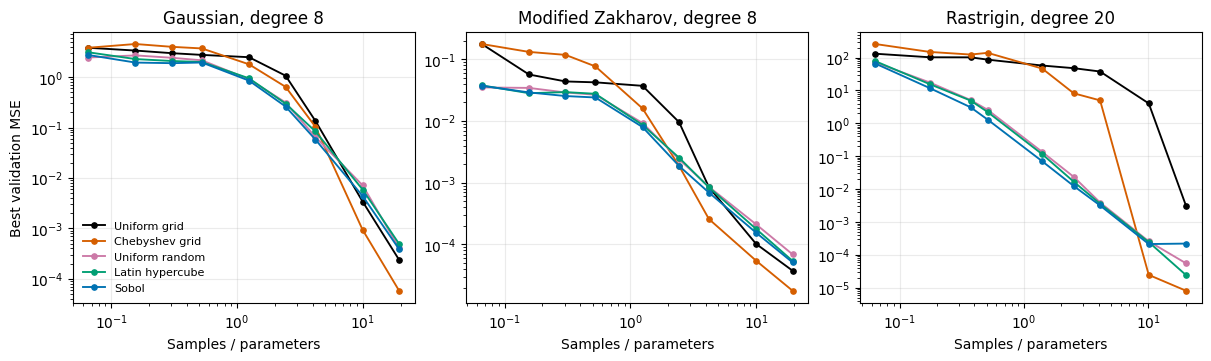

In [6]:
def plot_methods(ax, curves):
    ax.loglog(
        curves["uniform_grid"]["ratio"],
        curves["uniform_grid"]["mean"],
        "o-",
        color="#000000",
        linewidth=1.35,
        markersize=3.8,
        label="Uniform grid",
    )
    ax.loglog(
        curves["chebyshev_grid"]["ratio"],
        curves["chebyshev_grid"]["mean"],
        "o-",
        color="#D55E00",
        linewidth=1.35,
        markersize=3.8,
        label="Chebyshev grid",
    )
    ax.loglog(
        curves["random"]["ratio"],
        curves["random"]["mean"],
        "o-",
        color="#CC79A7",
        linewidth=1.35,
        markersize=3.8,
        label="Uniform random",
    )
    ax.loglog(
        curves["latin"]["ratio"],
        curves["latin"]["mean"],
        "o-",
        color="#009E73",
        linewidth=1.35,
        markersize=3.8,
        label="Latin hypercube",
    )
    ax.loglog(
        curves["sobol"]["ratio"],
        curves["sobol"]["mean"],
        "o-",
        color="#0072B2",
        linewidth=1.35,
        markersize=3.8,
        label="Sobol",
    )
    if len(SEEDS) > 1:
        ax.fill_between(
            curves["uniform_grid"]["ratio"],
            curves["uniform_grid"]["lower"],
            curves["uniform_grid"]["upper"],
            color="#000000",
            alpha=0.12,
            linewidth=0,
        )
        ax.fill_between(
            curves["chebyshev_grid"]["ratio"],
            curves["chebyshev_grid"]["lower"],
            curves["chebyshev_grid"]["upper"],
            color="#D55E00",
            alpha=0.12,
            linewidth=0,
        )
        ax.fill_between(
            curves["random"]["ratio"],
            curves["random"]["lower"],
            curves["random"]["upper"],
            color="#CC79A7",
            alpha=0.12,
            linewidth=0,
        )
        ax.fill_between(
            curves["latin"]["ratio"],
            curves["latin"]["lower"],
            curves["latin"]["upper"],
            color="#009E73",
            alpha=0.12,
            linewidth=0,
        )
        ax.fill_between(
            curves["sobol"]["ratio"],
            curves["sobol"]["lower"],
            curves["sobol"]["upper"],
            color="#0072B2",
            alpha=0.12,
            linewidth=0,
        )
    ax.set_xlabel("Samples / parameters")
    ax.grid(True, alpha=0.25)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
plot_methods(axes[0], results["Gaussian"])
axes[0].set(title="Gaussian, degree 8", ylabel="Best validation MSE")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plot_methods(axes[1], results["Modified Zakharov"])
axes[1].set(title="Modified Zakharov, degree 8")
plot_methods(axes[2], results["Rastrigin"])
axes[2].set(title="Rastrigin, degree 20")
plt.show()
